# COM7021 Data Visualisation: EcoMove urban mobility investigation

Student ID: **[STUDENT ID]**

This notebook explores the EcoMove City Transport Authority dataset and produces the static figures used in the report. The interactive dashboard is in `dashboard/app.py`.

## 1. Set-up

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
MODES = ["Metro", "Tram", "Bus", "Park and Ride", "Bike Share", "E-Scooter"]
MICRO = ["Bike Share", "E-Scooter"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
TOL = ["#4477AA", "#EE6677", "#228833", "#CCBB44", "#66CCEE", "#AA3377"]
MODE_COLOURS = dict(zip(MODES, TOL))
GREY = "#BBBBBB"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIG_DIR / name, facecolor="white")
    plt.show()

## 2. Loading the data

In [2]:
raw = pd.read_excel("[5442] EcoMoveMobility.xlsx", sheet_name="Dataset")
print("Shape:", raw.shape)
print("Date column type before conversion:", raw["Date"].dtype)
raw.head(3).T

Shape: (5000, 18)
Date column type before conversion: int64


,0,1,2
Record_ID,EM-00001,EM-00002,EM-00003
Date,45747,45717,45882
City,Paris,Paris,Rotterdam
Country,France,France,Netherlands
Transport_Mode,Tram,Tram,Tram
Route_Type,Tourist Zone,University Area,Airport Connector
Weather,Cloudy,Cloudy,Clear
Event_Day,Yes,No,No
Passengers,22946,9417,6467
Trips,101,59,38


## 3. Data quality checks

In [3]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "zeros": (raw == 0).sum(),
    "unique": raw.nunique(),
})
print(quality)
print("Duplicate rows (ignoring Record_ID):", raw.drop(columns="Record_ID").duplicated().sum())
print("Duplicate Record_IDs:", raw["Record_ID"].duplicated().sum())

                            dtype  missing  zeros  unique
Record_ID                     str        0      0    5000
Date                        int64        0      0     729
City                          str        0      0      12
Country                       str        0      0       6
Transport_Mode                str        0      0       6
Route_Type                    str        0      0       6
Weather                       str        0      0       6
Event_Day                     str        0      0       2
Passengers                  int64        0      0    3856
Trips                       int64        0      0     615
Average_Delay_Minutes     float64        0    185     121
On_Time_Percentage        float64        0      0     390
Ticket_Revenue_EUR        float64        0      0    4986
Operating_Cost_EUR        float64        0      0    4994
CO2_Saved_KG              float64        0      0    3991
Energy_Consumption_KWh    float64        0    759    3258
Customer_Ratin

In [4]:
df = raw.copy()
df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30")
full_range = pd.date_range(df["Date"].min(), df["Date"].max())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Days with no records:", [d.date() for d in full_range.difference(df["Date"].unique())])
print("On-time % range:", df["On_Time_Percentage"].min(), "-", df["On_Time_Percentage"].max())
print("Rating range:", df["Customer_Rating"].min(), "-", df["Customer_Rating"].max())
print("Negative values in numeric columns:", int((df.select_dtypes("number") < 0).sum().sum()))
print("Zero-energy rows by mode:", df.loc[df["Energy_Consumption_KWh"] == 0, "Transport_Mode"].value_counts().to_dict())
print("Zero-complaint rows by mode:", df.loc[df["Accessibility_Complaints"] == 0, "Transport_Mode"].value_counts().to_dict())
print("City-to-country pairs:", df.groupby("City")["Country"].nunique().max(), "country per city")

Date range: 2024-01-01 to 2025-12-31
Days with no records: [datetime.date(2024, 2, 18), datetime.date(2025, 1, 16)]
On-time % range: 55.0 - 99.0
Rating range: 2.7 - 4.9
Negative values in numeric columns: 0
Zero-energy rows by mode: {'Bike Share': 759}
Zero-complaint rows by mode: {'Bike Share': 353, 'E-Scooter': 213}
City-to-country pairs: 1 country per city


## 4. Feature engineering

In [5]:
df["YearMonth"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Year"] = df["Date"].dt.year
df["Weekday"] = pd.Categorical(df["Date"].dt.day_name(), categories=WEEKDAYS, ordered=True)
df["Is_Weekend"] = df["Date"].dt.dayofweek >= 5
df["Transport_Mode"] = pd.Categorical(df["Transport_Mode"], categories=MODES, ordered=True)
df["Revenue_per_Passenger"] = df["Ticket_Revenue_EUR"] / df["Passengers"]
df["Cost_per_Passenger"] = df["Operating_Cost_EUR"] / df["Passengers"]
df["Is_Micromobility"] = df["Transport_Mode"].isin(MICRO)


def recovery(d):
    return d["Ticket_Revenue_EUR"].sum() / d["Operating_Cost_EUR"].sum() * 100


def complaints_per_1k(d):
    return d["Accessibility_Complaints"].sum() / d["Passengers"].sum() * 1000


print("Network cost recovery: %.2f%%" % recovery(df))
print("Network complaints per 1,000 passengers: %.2f" % complaints_per_1k(df))
df[["Revenue_per_Passenger", "Cost_per_Passenger"]].describe().round(2)

Network cost recovery: 99.58%
Network complaints per 1,000 passengers: 1.53


,Revenue_per_Passenger,Cost_per_Passenger
count,5000.00,5000.00
mean,2.31,7.22
std,0.64,9.21
min,1.03,1.75
25%,2.11,2.29
50%,2.44,2.56
75%,2.76,3.02
max,3.42,35.65


## 5. Visualisation 1: reliability over time and by weather (small multiples and dot plot)

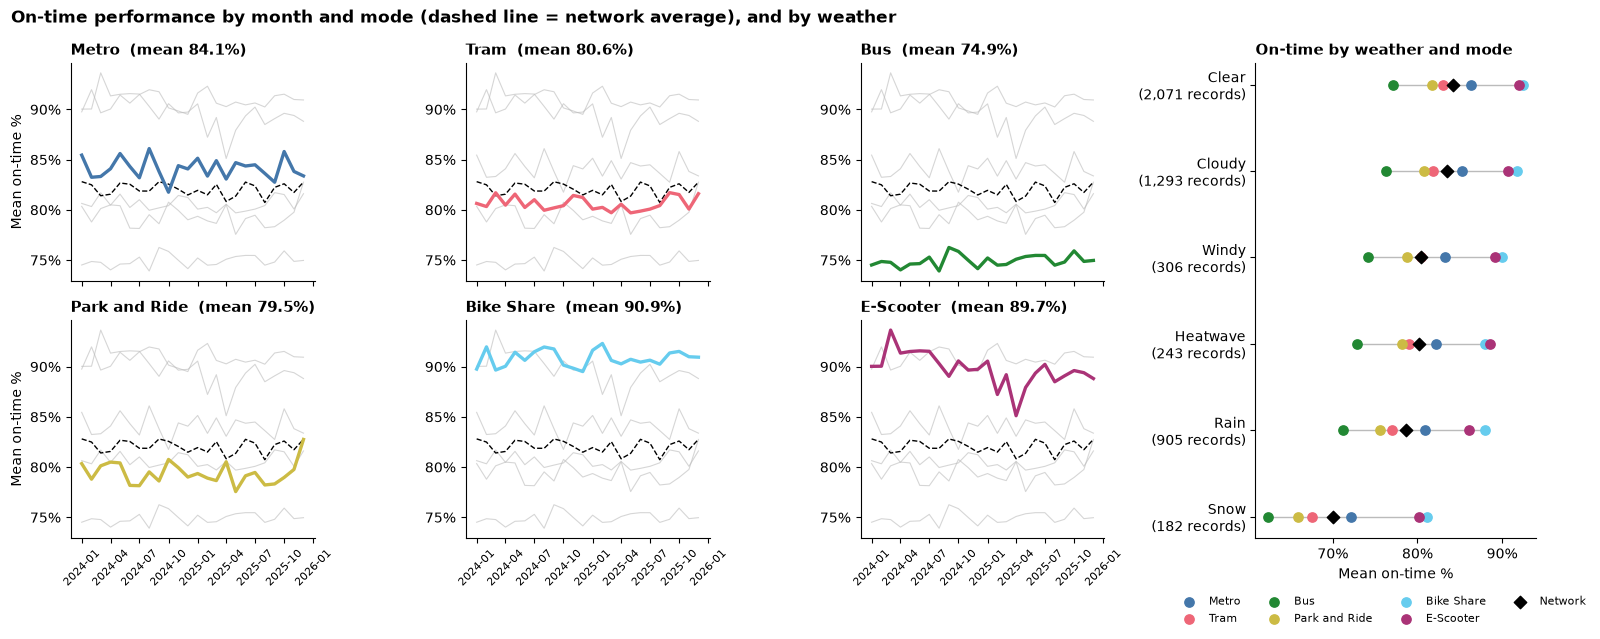

Bus ranked last in 24 of 24 months
Transport_Mode  Metro  Tram   Bus  Park and Ride  Bike Share  E-Scooter
min              81.8  79.7  73.9           77.6        89.5       85.1
max              86.1  81.7  76.3           82.8        92.3       93.6
Snow minus Clear on-time by mode (points): {'Metro': -14.2, 'Tram': -15.6, 'Bus': -14.7, 'Park and Ride': -15.7, 'Bike Share': -11.3, 'E-Scooter': -11.8}
Correlation of on-time percentage with delay minutes per record: -0.97


In [6]:
monthly = df.groupby(["YearMonth", "Transport_Mode"], observed=True)["On_Time_Percentage"].mean().unstack()
network = df.groupby("YearMonth")["On_Time_Percentage"].mean()
weather = df.pivot_table(index="Weather", columns="Transport_Mode", values="On_Time_Percentage", aggfunc="mean", observed=True)
weather_net = df.groupby("Weather")["On_Time_Percentage"].mean().sort_values()
weather = weather.loc[weather_net.index]
fig = plt.figure(figsize=(16, 6.5))
grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 1.15])
axes = [fig.add_subplot(grid[i // 3, i % 3]) for i in range(6)]
for ax in axes[1:]:
    ax.sharey(axes[0])
    ax.sharex(axes[0])
for ax, mode in zip(axes, MODES):
    for other in MODES:
        if other != mode:
            ax.plot(monthly.index, monthly[other], color=GREY, lw=0.8, alpha=0.6)
    ax.plot(network.index, network, color="black", lw=1, ls="--")
    ax.plot(monthly.index, monthly[mode], color=MODE_COLOURS[mode], lw=2.4)
    ax.set_title(f"{mode}  (mean {df.loc[df['Transport_Mode'] == mode, 'On_Time_Percentage'].mean():.1f}%)", fontsize=10.5)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    if mode in MODES[:3]:
        ax.tick_params(axis="x", labelbottom=False)
axes[0].set_ylabel("Mean on-time %")
axes[3].set_ylabel("Mean on-time %")
wx = fig.add_subplot(grid[:, 3])
y = np.arange(len(weather))
wx.hlines(y, weather.min(axis=1), weather.max(axis=1), color=GREY, lw=1)
for mode in MODES:
    wx.scatter(weather[mode], y, color=MODE_COLOURS[mode], s=45, label=mode, zorder=3)
wx.scatter(weather_net, y, color="black", marker="D", s=40, label="Network", zorder=4)
wx.set_yticks(y, [f"{w}\n({(df['Weather'] == w).sum():,} records)" for w in weather.index])
wx.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
wx.set_xlabel("Mean on-time %")
wx.set_title("On-time by weather and mode", fontsize=10.5)
wx.legend(loc="upper center", bbox_to_anchor=(0.45, -0.1), ncol=4, fontsize=8, frameon=False)
fig.suptitle("On-time performance by month and mode (dashed line = network average), and by weather",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "fig01_reliability_small_multiples.png")
rank = monthly.rank(axis=1, ascending=False)
print("Bus ranked last in", int((rank["Bus"] == 6).sum()), "of", len(rank), "months")
print(monthly.agg(["min", "max"]).round(1))
print("Snow minus Clear on-time by mode (points):", (weather.loc["Snow"] - weather.loc["Clear"]).round(1).to_dict())
print("Correlation of on-time percentage with delay minutes per record:", round(df["On_Time_Percentage"].corr(df["Average_Delay_Minutes"]), 2))

## 6. Visualisation 2: when and where demand concentrates (heatmaps)

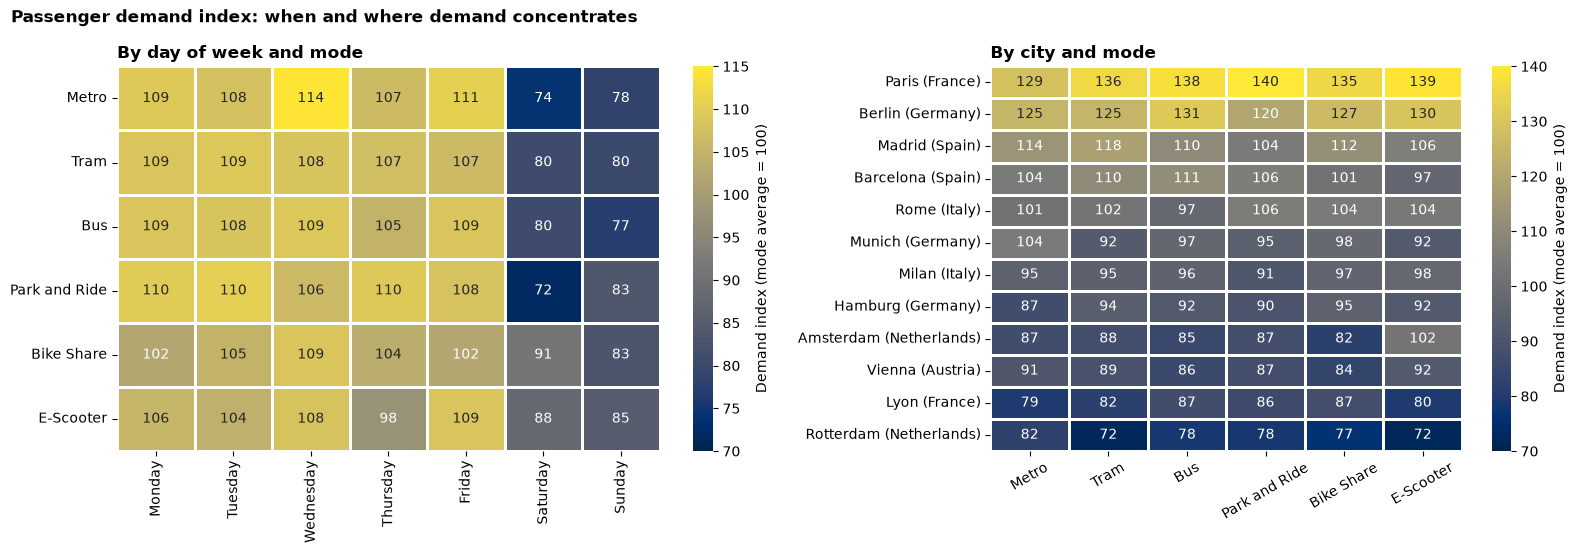

Weekend drop by mode (%):
Transport_Mode
Metro            30.6
Tram             25.7
Bus              27.2
Park and Ride    29.2
Bike Share       16.4
E-Scooter        17.6
dtype: float64
City demand index range within each mode:
Transport_Mode  Metro   Tram    Bus  Park and Ride  Bike Share  E-Scooter
min              79.0   72.0   78.0           78.0        77.0       72.0
max             129.0  136.0  138.0          140.0       135.0      139.0


In [7]:
weekday_mean = df.pivot_table(index="Transport_Mode", columns="Weekday", values="Passengers", aggfunc="mean", observed=True)
index = weekday_mean.div(df.groupby("Transport_Mode", observed=True)["Passengers"].mean(), axis=0) * 100
city_mean = df.pivot_table(index="City", columns="Transport_Mode", values="Passengers", aggfunc="mean", observed=True)
city_index = city_mean.div(df.groupby("Transport_Mode", observed=True)["Passengers"].mean(), axis=1) * 100
city_index = city_index.loc[city_index.mean(axis=1).sort_values(ascending=False).index]
country = df.groupby("City")["Country"].first()
city_index.index = [f"{c} ({country[c]})" for c in city_index.index]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
sns.heatmap(index, annot=True, fmt=".0f", cmap="cividis", vmin=70, vmax=115, linewidths=1, linecolor="white",
            cbar_kws={"label": "Demand index (mode average = 100)"}, ax=a1)
a1.set_xlabel("")
a1.set_ylabel("")
a1.set_title("By day of week and mode")
sns.heatmap(city_index, annot=True, fmt=".0f", cmap="cividis", vmin=70, vmax=140, linewidths=1, linecolor="white",
            cbar_kws={"label": "Demand index (mode average = 100)"}, ax=a2)
a2.set_xlabel("")
a2.set_ylabel("")
a2.tick_params(axis="x", labelrotation=30)
a2.set_title("By city and mode")
fig.suptitle("Passenger demand index: when and where demand concentrates", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "fig02_weekday_heatmap.png")
weekend = df.groupby(["Transport_Mode", "Is_Weekend"], observed=True)["Passengers"].mean().unstack()
print("Weekend drop by mode (%):")
print(((1 - weekend[True] / weekend[False]) * 100).round(1))
print("City demand index range within each mode:")
print(city_index.agg(["min", "max"]).round(0))

## 7. Visualisation 3: event-day demand uplift (dumbbell)

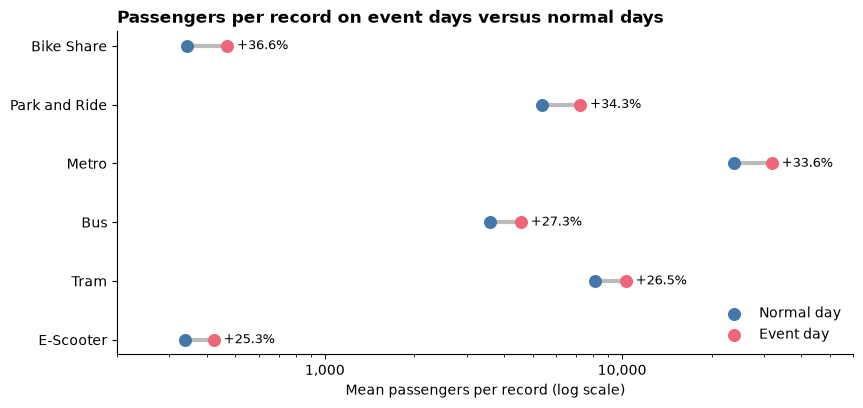

Event_Day,No,Yes,Uplift
Transport_Mode,,,
E-Scooter,337.6,422.8,25.3
Tram,8133.3,10284.6,26.5
Bus,3585.2,4562.6,27.3
Metro,23873.9,31890.3,33.6
Park and Ride,5379.9,7223.6,34.3
Bike Share,343.3,468.9,36.6


In [8]:
ev = df.pivot_table(index="Transport_Mode", columns="Event_Day", values="Passengers", aggfunc="mean", observed=True)
ev["Uplift"] = (ev["Yes"] / ev["No"] - 1) * 100
ev = ev.sort_values("Uplift")
fig, ax = plt.subplots(figsize=(9.5, 4.2))
y = np.arange(len(ev))
ax.hlines(y, ev["No"], ev["Yes"], color=GREY, lw=3)
ax.scatter(ev["No"], y, color="#4477AA", s=70, label="Normal day", zorder=3)
ax.scatter(ev["Yes"], y, color="#EE6677", s=70, label="Event day", zorder=3)
for i, (mode, row) in enumerate(ev.iterrows()):
    ax.text(row["Yes"] * 1.08, i, f"+{row['Uplift']:.1f}%", va="center", fontsize=9.5)
ax.set_yticks(y, ev.index)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(200, 60000)
ax.set_xlabel("Mean passengers per record (log scale)")
ax.set_title("Passengers per record on event days versus normal days")
ax.legend(frameon=False, loc="lower right")
save(fig, "fig03_event_dumbbell.png")
ev.round(1)

## 8. Visualisation 4: city cost recovery, 2024 versus 2025 (slope chart)

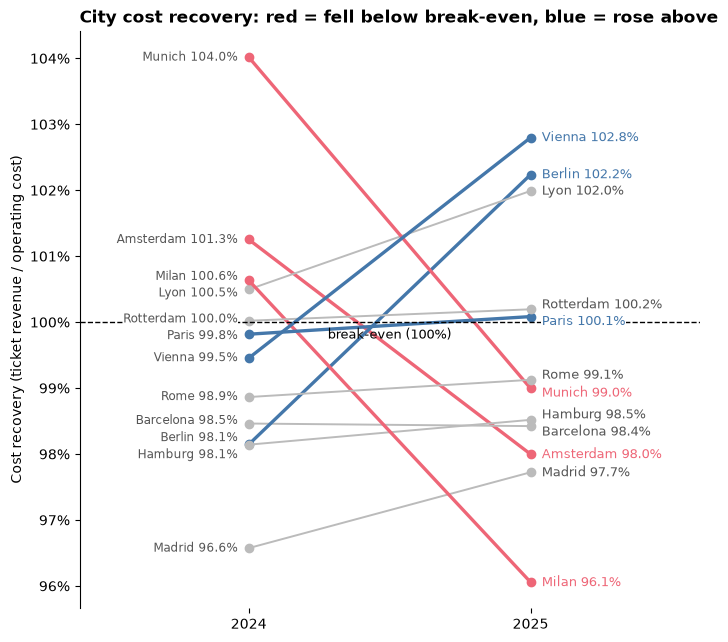

Year,2024,2025,Change
City,,,
Munich,104.0,99.0,-5.0
Milan,100.6,96.1,-4.6
Amsterdam,101.3,98.0,-3.3
Barcelona,98.5,98.4,-0.0
Rotterdam,100.0,100.2,0.2
Paris,99.8,100.1,0.3
Rome,98.9,99.1,0.3
Hamburg,98.1,98.5,0.4
Madrid,96.6,97.7,1.1


In [9]:
yearly = df.groupby(["City", "Year"]).apply(recovery, include_groups=False).unstack()


def spread(values, gap=0.26):
    order = np.argsort(values, kind="stable")
    placed = np.array(values, dtype=float)
    for _ in range(500):
        moved = False
        for i in range(1, len(order)):
            lo, hi = order[i - 1], order[i]
            overlap = gap - (placed[hi] - placed[lo])
            if overlap > 1e-6:
                placed[lo] -= overlap / 2
                placed[hi] += overlap / 2
                moved = True
        if not moved:
            break
    return placed


right_pos = dict(zip(yearly.index, spread(yearly[2025].values)))
left_pos = dict(zip(yearly.index, spread(yearly[2024].values)))
fig, ax = plt.subplots(figsize=(8, 7.5))
for city, row in yearly.iterrows():
    a, b = row[2024], row[2025]
    if a >= 100 > b:
        colour, lw = "#EE6677", 2.4
    elif a < 100 <= b:
        colour, lw = "#4477AA", 2.4
    else:
        colour, lw = GREY, 1.4
    ax.plot([0, 1], [a, b], color=colour, lw=lw, marker="o")
    box = {"facecolor": "white", "edgecolor": "none", "pad": 0.4}
    ax.text(1.04, right_pos[city], f"{city} {b:.1f}%", va="center", fontsize=9, bbox=box,
            color=colour if colour != GREY else "#555555")
    ax.text(-0.04, left_pos[city], f"{city} {a:.1f}%", va="center", ha="right", fontsize=8.5, bbox=box, color="#555555")
ax.axhline(100, color="black", ls="--", lw=1)
ax.text(0.5, 99.75, "break-even (100%)", ha="center", fontsize=9)
ax.set_xticks([0, 1], ["2024", "2025"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("Cost recovery (ticket revenue / operating cost)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.spines["bottom"].set_visible(False)
ax.set_title("City cost recovery: red = fell below break-even, blue = rose above")
save(fig, "fig04_city_recovery_slope.png")
yearly.assign(Change=yearly[2025] - yearly[2024]).round(1).sort_values("Change")

## 9. Visualisation 5: energy used versus CO2 saved (log-log scatter)

Rows excluded because Energy_Consumption_KWh = 0: 759


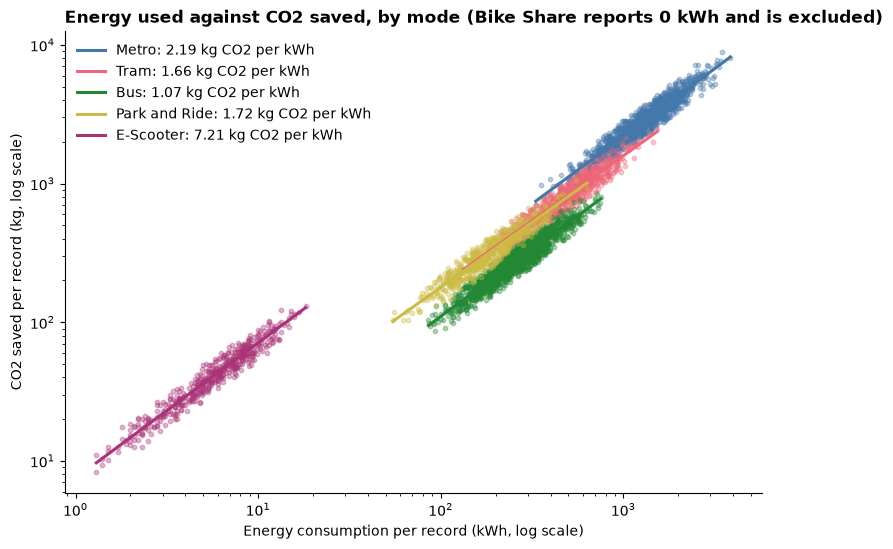

,Mode,kg_CO2_per_kWh,r_log,records
0,Metro,2.19,0.96,1047
1,Tram,1.66,0.95,761
2,Bus,1.07,0.95,1375
3,Park and Ride,1.72,0.95,585
4,E-Scooter,7.21,0.97,473


In [10]:
energy = df[df["Energy_Consumption_KWh"] > 0]
print("Rows excluded because Energy_Consumption_KWh = 0:", len(df) - len(energy))
fig, ax = plt.subplots(figsize=(9, 6))
rows = []
for mode in [m for m in MODES if m != "Bike Share"]:
    g = energy[energy["Transport_Mode"] == mode]
    eff = g["CO2_Saved_KG"].sum() / g["Energy_Consumption_KWh"].sum()
    ax.scatter(g["Energy_Consumption_KWh"], g["CO2_Saved_KG"], s=10, alpha=0.35, color=MODE_COLOURS[mode])
    lx, ly = np.log10(g["Energy_Consumption_KWh"]), np.log10(g["CO2_Saved_KG"])
    slope, intercept = np.polyfit(lx, ly, 1)
    xs = np.linspace(lx.min(), lx.max(), 50)
    ax.plot(10 ** xs, 10 ** (intercept + slope * xs), color=MODE_COLOURS[mode], lw=2.2,
            label=f"{mode}: {eff:.2f} kg CO2 per kWh")
    rows.append({"Mode": mode, "kg_CO2_per_kWh": eff, "r_log": np.corrcoef(lx, ly)[0, 1], "records": len(g)})
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Energy consumption per record (kWh, log scale)")
ax.set_ylabel("CO2 saved per record (kg, log scale)")
ax.set_title("Energy used against CO2 saved, by mode (Bike Share reports 0 kWh and is excluded)")
ax.legend(frameon=False, loc="upper left")
save(fig, "fig05_energy_co2_scatter.png")
pd.DataFrame(rows).round(2)

## 10. Visualisation 6: revenue and cost per passenger (split violin)

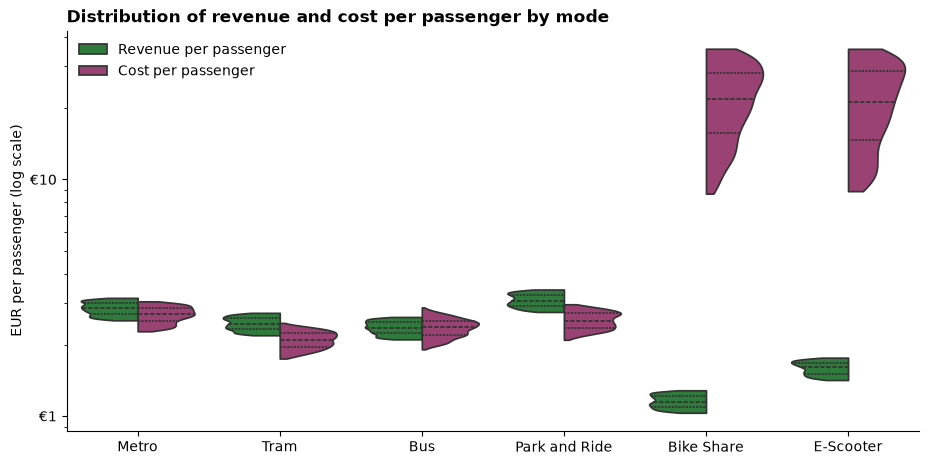

,Revenue_per_Passenger,Cost_per_Passenger,Loss-making records %
Transport_Mode,,,
Metro,2.85,2.69,27.13
Tram,2.45,2.10,5.65
Bus,2.36,2.37,50.76
Park and Ride,3.07,2.53,2.56
Bike Share,1.15,21.79,100.00
E-Scooter,1.60,21.27,100.00


In [11]:
unit = df.melt(id_vars="Transport_Mode", value_vars=["Revenue_per_Passenger", "Cost_per_Passenger"],
               var_name="Measure", value_name="EUR")
unit["Measure"] = unit["Measure"].map({"Revenue_per_Passenger": "Revenue per passenger",
                                       "Cost_per_Passenger": "Cost per passenger"})
fig, ax = plt.subplots(figsize=(11, 5.2))
sns.violinplot(data=unit, x="Transport_Mode", y="EUR", hue="Measure", split=True, inner="quart",
               palette={"Revenue per passenger": "#228833", "Cost per passenger": "#AA3377"},
               log_scale=True, cut=0, density_norm="width", ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"€{v:g}"))
ax.set_xlabel("")
ax.set_ylabel("EUR per passenger (log scale)")
ax.set_title("Distribution of revenue and cost per passenger by mode")
ax.legend(frameon=False, title="", loc="upper left")
save(fig, "fig06_unit_economics_violin.png")
summary = df.groupby("Transport_Mode", observed=True)[["Revenue_per_Passenger", "Cost_per_Passenger"]].median()
summary["Loss-making records %"] = df.groupby("Transport_Mode", observed=True).apply(
    lambda x: (x["Ticket_Revenue_EUR"] < x["Operating_Cost_EUR"]).mean() * 100, include_groups=False)
summary.round(2)

## 11. Visualisation 7: city cost recovery with and without micromobility (lollipop KPI)

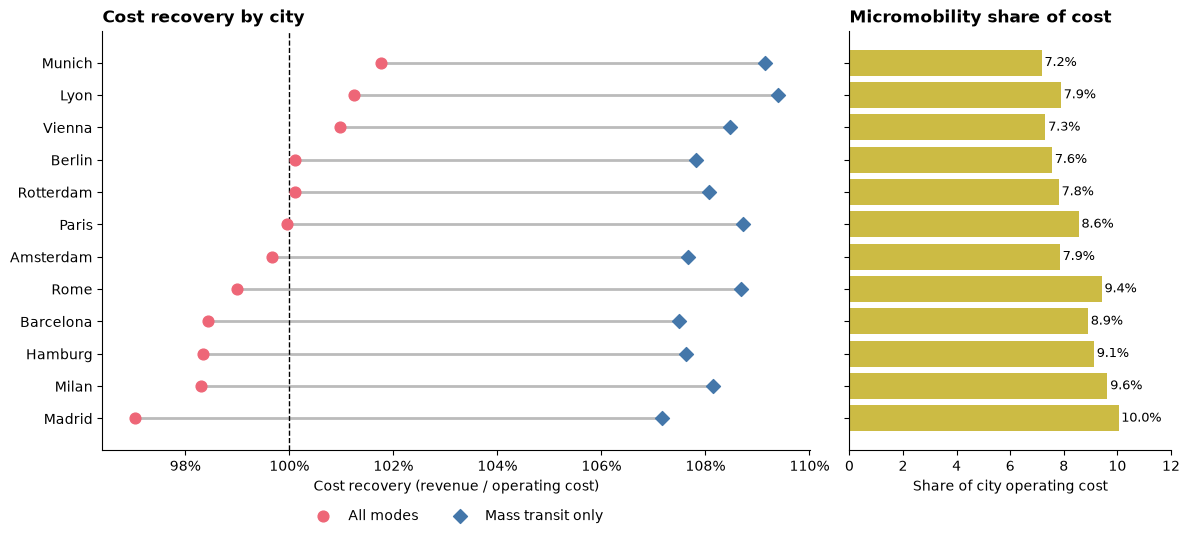

Correlation between micromobility cost share and city cost recovery: -0.91


,All modes,Mass transit only,Micromobility share of cost %
City,,,
Madrid,97.0,107.2,10.0
Milan,98.3,108.1,9.6
Hamburg,98.3,107.6,9.1
Barcelona,98.4,107.5,8.9
Rome,99.0,108.7,9.4
Amsterdam,99.7,107.7,7.9
Paris,100.0,108.7,8.6
Rotterdam,100.1,108.1,7.8
Berlin,100.1,107.8,7.6


In [12]:
city = pd.DataFrame({
    "All modes": df.groupby("City").apply(recovery, include_groups=False),
    "Mass transit only": df[~df["Is_Micromobility"]].groupby("City").apply(recovery, include_groups=False),
    "Micromobility share of cost %": df[df["Is_Micromobility"]].groupby("City")["Operating_Cost_EUR"].sum()
    / df.groupby("City")["Operating_Cost_EUR"].sum() * 100,
}).sort_values("All modes")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, gridspec_kw={"width_ratios": [2.2, 1]})
y = np.arange(len(city))
ax1.hlines(y, city["All modes"], city["Mass transit only"], color=GREY, lw=2)
ax1.scatter(city["All modes"], y, color="#EE6677", s=60, zorder=3, label="All modes")
ax1.scatter(city["Mass transit only"], y, color="#4477AA", marker="D", s=50, zorder=3, label="Mass transit only")
ax1.axvline(100, color="black", ls="--", lw=1)
ax1.set_yticks(y, city.index)
ax1.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.set_xlabel("Cost recovery (revenue / operating cost)")
ax1.set_title("Cost recovery by city")
ax1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2)
ax2.barh(y, city["Micromobility share of cost %"], color="#CCBB44")
for i, v in enumerate(city["Micromobility share of cost %"]):
    ax2.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9)
ax2.set_xlim(0, 12)
ax2.set_xlabel("Share of city operating cost")
ax2.set_title("Micromobility share of cost")
fig.tight_layout()
save(fig, "fig07_city_recovery_lollipop.png")
print("Correlation between micromobility cost share and city cost recovery: %.2f"
      % city["Micromobility share of cost %"].corr(city["All modes"]))
city.round(1)

## 12. Visualisation 8: accessibility priority matrix (bubble chart)

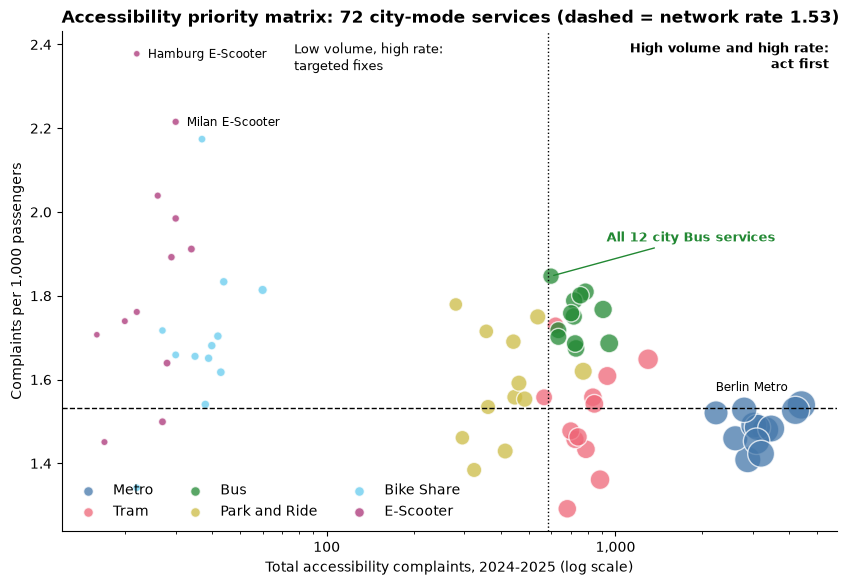

Transport_Mode
Bus              12
Tram              5
Metro             1
Park and Ride     1
Name: count, dtype: int64


In [13]:
cm = df.groupby(["City", "Transport_Mode"], observed=True).agg(
    complaints=("Accessibility_Complaints", "sum"), passengers=("Passengers", "sum")).reset_index()
cm["per_1k"] = cm["complaints"] / cm["passengers"] * 1000
net_rate = complaints_per_1k(df)
median_vol = cm["complaints"].median()
fig, ax = plt.subplots(figsize=(10, 6.5))
for mode in MODES:
    g = cm[cm["Transport_Mode"] == mode]
    ax.scatter(g["complaints"], g["per_1k"], s=np.sqrt(g["passengers"]) / 4, color=MODE_COLOURS[mode],
               alpha=0.75, edgecolor="white", label=mode)
ax.axvline(median_vol, color="black", ls=":", lw=1)
ax.axhline(net_rate, color="black", ls="--", lw=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.text(0.99, 0.98, "High volume and high rate:\nact first", transform=ax.transAxes, ha="right", va="top",
        fontsize=9.5, fontweight="bold")
ax.text(0.30, 0.98, "Low volume, high rate:\ntargeted fixes", transform=ax.transAxes, ha="left", va="top", fontsize=9.5)
for _, r in cm.nlargest(2, "per_1k").iterrows():
    ax.annotate(f"{r['City']} {r['Transport_Mode']}", (r["complaints"], r["per_1k"]), xytext=(8, -3),
                textcoords="offset points", fontsize=8.5)
bus = cm[cm["Transport_Mode"] == "Bus"]
top_bus = bus.loc[bus["per_1k"].idxmax()]
ax.annotate("All 12 city Bus services", (top_bus["complaints"], top_bus["per_1k"]), xytext=(40, 25),
            textcoords="offset points", fontsize=9, color="#228833", fontweight="bold",
            arrowprops={"arrowstyle": "-", "color": "#228833"})
for _, r in cm.nlargest(1, "complaints").iterrows():
    ax.annotate(f"{r['City']} {r['Transport_Mode']}", (r["complaints"], r["per_1k"]), xytext=(-10, 10),
                textcoords="offset points", fontsize=8.5, ha="right")
ax.set_xlabel("Total accessibility complaints, 2024-2025 (log scale)")
ax.set_ylabel("Complaints per 1,000 passengers")
ax.set_title(f"Accessibility priority matrix: 72 city-mode services (dashed = network rate {net_rate:.2f})")
leg = ax.legend(frameon=False, loc="lower left", ncol=3)
for h in leg.legend_handles:
    h.set_sizes([50])
save(fig, "fig08_accessibility_matrix.png")
cm["high_volume"] = cm["complaints"] >= median_vol
cm["high_rate"] = cm["per_1k"] >= net_rate
print(cm[cm["high_volume"] & cm["high_rate"]]["Transport_Mode"].astype(str).value_counts())

## 13. Visualisation 9: mode performance profiles (radar small multiples)

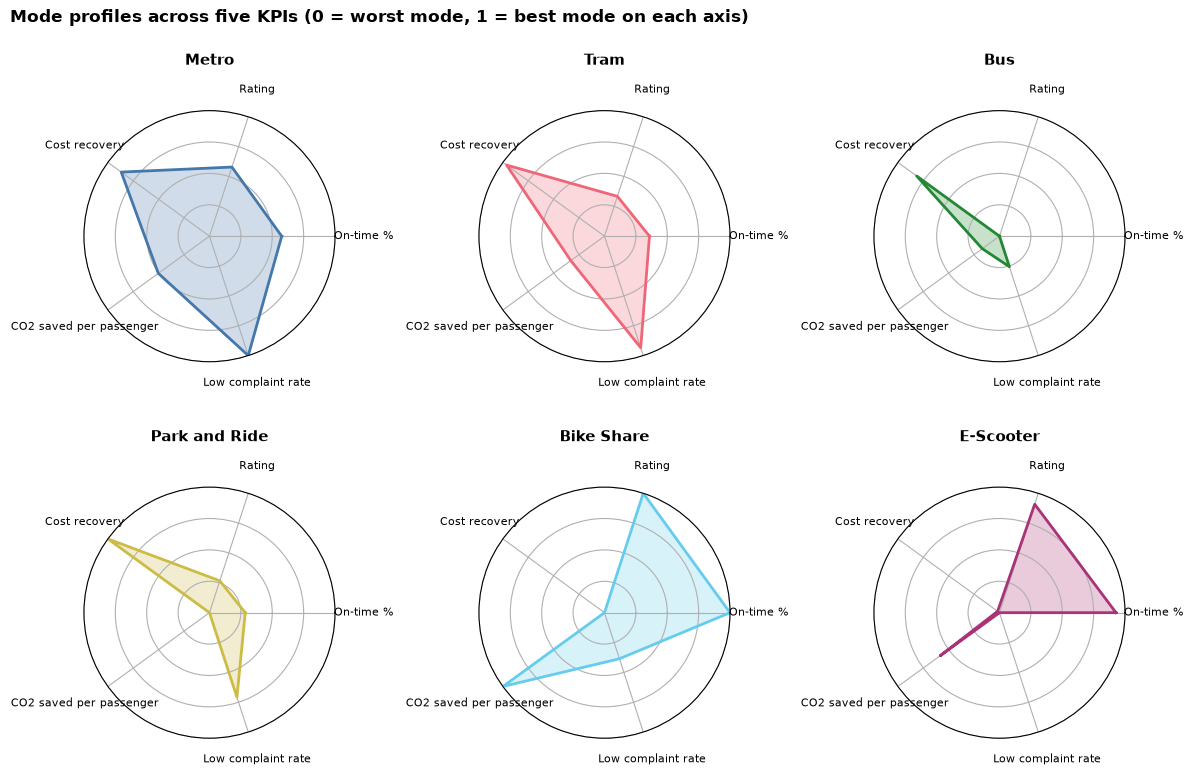

,On-time %,Rating,Cost recovery,CO2 saved per passenger,Low complaint rate
Transport_Mode,,,,,
Metro,84.086,4.092,106.236,0.122,1.485
Tram,80.629,3.943,117.297,0.101,1.508
Bus,74.922,3.740,100.081,0.082,1.746
Park and Ride,79.462,3.902,121.530,0.061,1.587
Bike Share,90.850,4.349,5.249,0.183,1.700
E-Scooter,89.707,4.293,7.387,0.132,1.836


In [14]:
prof = pd.DataFrame({
    "On-time %": df.groupby("Transport_Mode", observed=True)["On_Time_Percentage"].mean(),
    "Rating": df.groupby("Transport_Mode", observed=True)["Customer_Rating"].mean(),
    "Cost recovery": df.groupby("Transport_Mode", observed=True).apply(recovery, include_groups=False),
    "CO2 saved per passenger": df.groupby("Transport_Mode", observed=True).apply(
        lambda x: x["CO2_Saved_KG"].sum() / x["Passengers"].sum(), include_groups=False),
    "Low complaint rate": df.groupby("Transport_Mode", observed=True).apply(complaints_per_1k, include_groups=False),
})
scaled = (prof - prof.min()) / (prof.max() - prof.min())
scaled["Low complaint rate"] = 1 - scaled["Low complaint rate"]
labels = list(scaled.columns)
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]
fig, axes = plt.subplots(2, 3, figsize=(12, 8), subplot_kw={"polar": True})
for ax, mode in zip(axes.flat, MODES):
    vals = scaled.loc[mode].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=MODE_COLOURS[mode], lw=2)
    ax.fill(angles, vals, color=MODE_COLOURS[mode], alpha=0.25)
    ax.set_xticks(angles[:-1], labels, fontsize=8)
    ax.tick_params(axis="x", pad=10)
    ax.set_yticks([0.25, 0.5, 0.75, 1], [])
    ax.set_ylim(0, 1)
    ax.set_title(mode, fontsize=11, pad=14, loc="center")
fig.suptitle("Mode profiles across five KPIs (0 = worst mode, 1 = best mode on each axis)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "fig09_mode_radar.png")
prof.round(3)

## 14. Summary table of headline indicators by mode

In [15]:
headline = pd.DataFrame({
    "Passenger share %": df.groupby("Transport_Mode", observed=True)["Passengers"].sum() / df["Passengers"].sum() * 100,
    "On-time %": prof["On-time %"],
    "Cost recovery %": prof["Cost recovery"],
    "kg CO2 per kWh": energy.groupby("Transport_Mode", observed=True).apply(
        lambda x: x["CO2_Saved_KG"].sum() / x["Energy_Consumption_KWh"].sum(), include_groups=False),
    "Complaints per 1k": prof["Low complaint rate"],
}).round(2)
headline

,Passenger share %,On-time %,Cost recovery %,kg CO2 per kWh,Complaints per 1k
Transport_Mode,,,,,
Metro,62.96,84.09,106.24,2.19,1.48
Tram,15.60,80.63,117.30,1.66,1.51
Bus,12.40,74.92,100.08,1.07,1.75
Park and Ride,7.98,79.46,121.53,1.72,1.59
Bike Share,0.66,90.85,5.25,NaN,1.70
E-Scooter,0.40,89.71,7.39,7.21,1.84
